In [1]:
# Get companies from wikipedia

import bs4 as bs
import pickle
import requests

resp = requests.get('http://en.wikipedia.org/wiki/List_of_S%26P_500_companies')
soup = bs.BeautifulSoup(resp.text, 'lxml')
table = soup.find('table', {'class': 'wikitable sortable'})
tickers = []
for row in table.findAll('tr')[1:]:
    ticker = row.findAll('td')[0].text.replace('.', '-')
    ticker = ticker[:-1]
    tickers.append(ticker)
tickers.append('SPY')
with open("sp500tickers.pickle", "wb") as f:
    pickle.dump(tickers, f)

In [ ]:
# Save stock prices from different websites

import datetime as dt
import os
import pandas_datareader.data as pdr
import pickle
import yfinance as yf
import quandl
import pandas as pd

with open("sp500tickers.pickle", "rb") as f:
    tickers = pickle.load(f)
if not os.path.exists('stock_dfs_yahoo'):
    os.makedirs('stock_dfs_yahoo')
if not os.path.exists('stock_dfs_quandl'):
    os.makedirs('stock_dfs_quandl')
    
start = dt.datetime(2000, 1, 1)
end = dt.datetime.now()
quandl.ApiConfig.api_key = 'Jhqb32mQMCCscxYLrLLS'

print("SPY")
if not os.path.exists('stock_dfs_yahoo/SPY_yahoo.csv'):
    df = pdr.get_data_yahoo("SPY", start, end)
    df.reset_index(inplace=True)
    df.set_index("Date", inplace=True)
    df.to_csv('stock_dfs_yahoo/SPY.csv')
else:
    print('Already have SPY from Yahoo')

for ticker in tickers:
    print(ticker)
    if not os.path.exists('stock_dfs_yahoo/{}.csv'.format(ticker)):
        df = pdr.get_data_yahoo(ticker, start, end)
        df.reset_index(inplace=True)
        df.set_index("Date", inplace=True)
        df.to_csv('stock_dfs_yahoo/{}.csv'.format(ticker))
    else:
        print('Already have {} from yahoo'.format(ticker))

    if not os.path.exists('stock_dfs_quandl/{}.csv'.format(ticker)):
        data = quandl.get_table('WIKI/PRICES', ticker = ticker, 
                        date = { 'gte': start, 'lte': end }, 
                        paginate=True)
        df = data.set_index('date')
        df.to_csv('stock_dfs_quandl/{}.csv'.format(ticker))
    else:
        print('Already have {} from quandl'.format(ticker))

<AxesSubplot:xlabel='Date'>

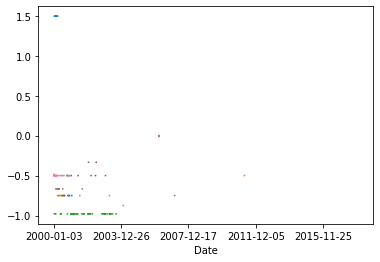

In [155]:
import numpy as np

df = pd.DataFrame().reindex_like(main_daily_return_quandl_df)
for ticker in tickers:
    zero_series_yahoo = daily_return_yahoo_df[ticker][daily_return_yahoo_df[ticker]==0]
    zero_series_quandl = daily_return_quandl_df[ticker][daily_return_quandl_df[ticker]==0]
    for date in zero_series_yahoo.index:
        if (daily_return_quandl_df.index == date).any() and daily_return_quandl_df[ticker][date] != 0 and not np.isnan(daily_return_quandl_df[ticker][date]):
            df[ticker][date] = daily_return_quandl_df[ticker][date]
df.plot(legend=False)

In [165]:
import numpy as np

for ticker in tickers:
    zero_series_yahoo = daily_return_yahoo_df[ticker][daily_return_yahoo_df[ticker]==0]
    for date in zero_series_yahoo.index:
        if (daily_return_quandl_df.index == date).any() and daily_return_quandl_df[ticker][date] != 0 and not np.isnan(daily_return_quandl_df[ticker][date]):
            daily_return_yahoo_df[ticker][date] = daily_return_quandl_df[ticker][date]
    print("zero values in {0}: {1}".format(ticker,(daily_return_yahoo_df[ticker] == 0).sum()))

zero values in MMM: 0
zero values in ABT: 0
zero values in ABBV: 0
zero values in ABMD: 47
zero values in ACN: 0
zero values in ATVI: 0
zero values in ADBE: 17
zero values in AMD: 104
zero values in AAP: 0
zero values in AES: 0
zero values in AFL: 0
zero values in A: 0
zero values in APD: 0
zero values in AKAM: 35
zero values in ALK: 0
zero values in ALB: 0
zero values in ARE: 0
zero values in ALXN: 2
zero values in ALGN: 51
zero values in ALLE: 0
zero values in LNT: 0
zero values in ALL: 0
zero values in GOOGL: 0
zero values in GOOG: 3
zero values in MO: 0
zero values in AMZN: 21
zero values in AMCR: 0
zero values in AEE: 0
zero values in AAL: 0
zero values in AEP: 0
zero values in AXP: 0
zero values in AIG: 0
zero values in AMT: 0
zero values in AWK: 0
zero values in AMP: 0
zero values in ABC: 0
zero values in AME: 0
zero values in AMGN: 0
zero values in APH: 0
zero values in ADI: 0
zero values in ANSS: 9
zero values in ANTM: 0
zero values in AON: 0
zero values in AOS: 0
zero values 

zero values in RMD: 0
zero values in RHI: 0
zero values in ROK: 0
zero values in ROL: 0
zero values in ROP: 0
zero values in ROST: 0
zero values in RCL: 0
zero values in SPGI: 0
zero values in CRM: 6
zero values in SBAC: 0
zero values in SLB: 0
zero values in STX: 0
zero values in SEE: 0
zero values in SRE: 0
zero values in NOW: 1
zero values in SHW: 0
zero values in SPG: 0
zero values in SWKS: 0
zero values in SLG: 0
zero values in SNA: 0
zero values in SO: 0
zero values in LUV: 0
zero values in SWK: 0
zero values in SBUX: 0
zero values in STT: 0
zero values in STE: 0
zero values in SYK: 0
zero values in SIVB: 24
zero values in SYF: 0
zero values in SNPS: 56
zero values in SYY: 0
zero values in TMUS: 6
zero values in TROW: 0
zero values in TTWO: 32
zero values in TPR: 0
zero values in TGT: 0
zero values in TEL: 0
zero values in FTI: 0
zero values in TDY: 61
zero values in TFX: 0
zero values in TER: 0
zero values in TXN: 0
zero values in TXT: 0
zero values in TMO: 0
zero values in TIF: